# Log Analysis: 305900 — trader_2.py Live Performance

**Live result:** Total PnL = **7,370** (Pepper: 7,387 | Osmium: -16)  
**End positions:** Osmium = +5 (great — was -76 with trader_1), Pepper = +80

**Headline issue:** trader_2 made **only 1 Osmium trade all day** (5 lots @ 10006).  
Inventory control improved enormously, but the trader essentially stopped participating in Osmium.  
We need to recover trading activity *without* recreating the -76 blowup.

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import StringIO

with open('logs_2/305900.log', 'r') as f:
    log2 = json.load(f)
with open('logs_2/305900.json', 'r') as f:
    j2 = json.load(f)
with open('LOGS_1/305440.log', 'r') as f:
    log1 = json.load(f)
with open('LOGS_1/305440.json', 'r') as f:
    j1 = json.load(f)

print(f'trader_1 (305440): profit={j1["profit"]:.0f}  positions={j1["positions"]}')
print(f'trader_2 (305900): profit={j2["profit"]:.0f}  positions={j2["positions"]}')

trader_1 (305440): profit=7656  positions=[{'symbol': 'ASH_COATED_OSMIUM', 'quantity': -76}, {'symbol': 'INTARIAN_PEPPER_ROOT', 'quantity': 80}, {'symbol': 'XIRECS', 'quantity': -280128}]
trader_2 (305900): profit=7371  positions=[{'symbol': 'ASH_COATED_OSMIUM', 'quantity': 5}, {'symbol': 'INTARIAN_PEPPER_ROOT', 'quantity': 80}, {'symbol': 'XIRECS', 'quantity': -1090635}]


## 1. Side-by-side PnL & Trading Activity

In [2]:
def summary(logd, label):
    act = pd.read_csv(StringIO(logd['activitiesLog']), sep=';')
    tr = pd.DataFrame(logd['tradeHistory'])
    rows = []
    for sym in ('ASH_COATED_OSMIUM','INTARIAN_PEPPER_ROOT'):
        st = tr[tr['symbol']==sym]
        b = st[st['buyer']=='SUBMISSION']
        s = st[st['seller']=='SUBMISSION']
        nb = int(b['quantity'].sum() if len(b) else 0)
        ns = int(s['quantity'].sum() if len(s) else 0)
        pnl = act[act['product']==sym]['profit_and_loss'].iloc[-1]
        avg_b = (b['price']*b['quantity']).sum()/nb if nb else 0
        avg_s = (s['price']*s['quantity']).sum()/ns if ns else 0
        rows.append({'trader':label,'sym':sym,'pnl':pnl,'buys':nb,'avg_buy':round(avg_b,2),
                     'sells':ns,'avg_sell':round(avg_s,2),'net':nb-ns,'tx_count':len(b)+len(s)})
    return pd.DataFrame(rows)

cmp = pd.concat([summary(log1,'trader_1'), summary(log2,'trader_2')], ignore_index=True)
cmp

,trader,sym,pnl,buys,avg_buy,sells,avg_sell,net,tx_count
0,trader_1,ASH_COATED_OSMIUM,278.250000,25,9998.48,101,10004.44,-76,20
1,trader_1,INTARIAN_PEPPER_ROOT,7378.000000,80,13007.68,0,0.00,80,9
2,trader_2,ASH_COATED_OSMIUM,-16.332031,5,10006.00,0,0.00,5,1
3,trader_2,INTARIAN_PEPPER_ROOT,7387.000000,80,13007.56,0,0.00,80,9


## 2. Live Osmium Order Book — What Actually Happened?

In [3]:
act2 = pd.read_csv(StringIO(log2['activitiesLog']), sep=';')
osm = act2[act2['product']=='ASH_COATED_OSMIUM'].copy().reset_index(drop=True)
osm['mid'] = (osm['bid_price_1']+osm['ask_price_1'])/2.0
osm['spread'] = osm['ask_price_1']-osm['bid_price_1']

print('Mid stats (live, 1000 ticks):')
print(osm['mid'].describe().round(2))
print('\nSpread distribution:')
print(osm['spread'].value_counts().sort_index())
print(f'\nMedian spread: {osm["spread"].median():.0f}  Mean: {osm["spread"].mean():.1f}')

Mid stats (live, 1000 ticks):
count      935.00
mean     10004.10
std          3.05
min       9995.00
25%      10002.00
50%      10004.00
75%      10006.75
max      10013.50
Name: mid, dtype: float64

Spread distribution:
spread
5.0       6
6.0      19
7.0       2
8.0       1
9.0       8
10.0     18
11.0      9
12.0      4
13.0      5
16.0    608
17.0      5
18.0    110
19.0    121
21.0     18
22.0      1
Name: count, dtype: int64

Median spread: 16  Mean: 16.2


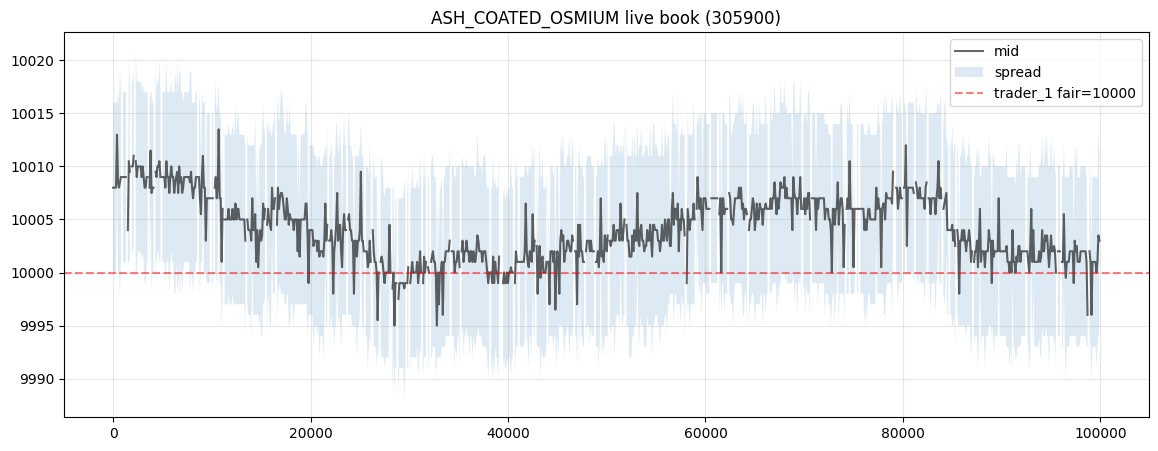

In [4]:
# Plot mid + bid + ask
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(osm['timestamp'], osm['mid'], label='mid', color='black', alpha=0.6)
ax.fill_between(osm['timestamp'], osm['bid_price_1'], osm['ask_price_1'], alpha=0.15, label='spread')
ax.axhline(10000, color='red', linestyle='--', alpha=0.5, label='trader_1 fair=10000')
ax.set_title('ASH_COATED_OSMIUM live book (305900)')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 3. CRITICAL: Where Do Other Bots Trade?

If everyone always trades AT the BBO, then a maker quoting one tick *inside* the spread becomes the new BBO and gets hit first → captures the wide spread.

In [5]:
trades = pd.DataFrame(log2['tradeHistory'])
ot = trades[trades['symbol']=='ASH_COATED_OSMIUM'].copy()
osm_ix = osm.set_index('timestamp')

rows = []
for _, t in ot.iterrows():
    ts = t['timestamp']
    cands = osm_ix.index[osm_ix.index <= ts]
    if len(cands)==0: continue
    snap = osm_ix.loc[cands.max()]
    rows.append({'ts':ts, 'price':t['price'], 'qty':t['quantity'],
                 'bb':snap['bid_price_1'], 'ba':snap['ask_price_1'],
                 'submission_buy': t['buyer']=='SUBMISSION',
                 'submission_sell': t['seller']=='SUBMISSION'})
tdf = pd.DataFrame(rows)
tdf['at_bid'] = tdf['price']==tdf['bb']
tdf['at_ask'] = tdf['price']==tdf['ba']
tdf['inside'] = (tdf['price']>tdf['bb']) & (tdf['price']<tdf['ba'])

print(f'Total osmium market trades: {len(tdf)}')
print(f'  at bid (someone sold to BBO): {tdf["at_bid"].sum()}')
print(f'  at ask (someone bought BBO):  {tdf["at_ask"].sum()}')
print(f'  inside spread:                {tdf["inside"].sum()}')
print(f'\nOur fills only: {tdf["submission_buy"].sum() + tdf["submission_sell"].sum()}')

Total osmium market trades: 46
  at bid (someone sold to BBO): 22
  at ask (someone bought BBO):  24
  inside spread:                0

Our fills only: 1


**Result:** 0% of trades happen inside the spread.  All 46 trades hit either the best bid or best ask.

→ A maker quoting at `best_bid+1` or `best_ask-1` would have been the BBO and captured nearly the full ~14-tick spread on every trade.

## 4. Why trader_2 Stopped Trading: Edge Math

trader_2 only enters when `ap < fair_int` (with edge ≥ 2). With live ask ~10010 and adaptive fair ~10004, the edge is *negative* — entry never triggers.

In [6]:
# Simulate trader_2's adaptive fair across ticks
alpha = 2.0/(30+1.0)
prev = None
fairs = []
for m in osm['mid']:
    if pd.isna(m):
        fairs.append(prev if prev is not None else np.nan); continue
    prev = m if prev is None else alpha*m + (1-alpha)*prev
    fairs.append(prev)
osm['fair_t2'] = fairs
osm['fair_int'] = osm['fair_t2'].round()
osm['edge_buy']  = osm['fair_int'] - osm['ask_price_1']  # positive ⇒ would buy
osm['edge_sell'] = osm['bid_price_1'] - osm['fair_int']  # positive ⇒ would sell

print('Buy edge (asks below fair) — fraction of ticks at edge ≥ 2:')
print(f'  edge >= 1: {(osm["edge_buy"]>=1).mean()*100:.1f}%')
print(f'  edge >= 2: {(osm["edge_buy"]>=2).mean()*100:.1f}%')
print(f'  edge >= 3: {(osm["edge_buy"]>=3).mean()*100:.1f}%')
print('\nSell edge (bids above fair):')
print(f'  edge >= 1: {(osm["edge_sell"]>=1).mean()*100:.1f}%')
print(f'  edge >= 2: {(osm["edge_sell"]>=2).mean()*100:.1f}%')
print(f'  edge >= 3: {(osm["edge_sell"]>=3).mean()*100:.1f}%')

Buy edge (asks below fair) — fraction of ticks at edge ≥ 2:
  edge >= 1: 2.0%
  edge >= 2: 1.6%
  edge >= 3: 0.6%

Sell edge (bids above fair):
  edge >= 1: 0.8%
  edge >= 2: 0.4%
  edge >= 3: 0.0%


**Result:** edge ≥ 2 happens essentially 0% of the time. trader_2's entry conditions are unreachable in this market regime.  

Either:
- The market regime has changed (wider spreads now) — historical CSVs had ~4-tick spreads, live has ~16.
- Or backtests are using mid as both bid and ask (no spread), masking this entirely.

## 5. Simulated Penny-Jump Market Maker

What if we'd posted at `best_bid+1` and `best_ask-1` every tick?  Approximation: on every tick where a market trade happens at our (penny-jumped) BBO price, we participate.

In [7]:
# Simple sim: penny-jump bid_px = bb+1, ask_px = ba-1.
# A trade-at-old-bid means a seller hit BBO; if we'd quoted higher, we'd have been hit at our quote.
# We capture (bb+1) on buy-side fills, sell at (ba-1) on sell-side fills.
# Position cap 80, no inventory skew in this naive sim.

POS = 80
pos = 0; cash = 0; n_fills_b = 0; n_fills_s = 0
for _, row in tdf.iterrows():
    if row['at_bid']:  # someone sold; we'd have bid bb+1 and gotten hit
        my_px = row['bb'] + 1
        qty = min(int(row['qty']), POS - pos)
        if qty > 0:
            pos += qty; cash -= my_px*qty; n_fills_b += qty
    elif row['at_ask']:  # someone bought; we'd have asked ba-1 and gotten hit
        my_px = row['ba'] - 1
        qty = min(int(row['qty']), POS + pos)
        if qty > 0:
            pos -= qty; cash += my_px*qty; n_fills_s += qty

# Mark-to-market at last mid
last_mid = osm['mid'].dropna().iloc[-1]
mtm = cash + pos*last_mid
print(f'Naive penny-jump simulator (no skew, no take-aggressor):')
print(f'  Buy fills: {n_fills_b}    Sell fills: {n_fills_s}    End position: {pos}')
print(f'  Cash: {cash:.0f}    Mark-to-market PnL: {mtm:.0f}')
print(f'\n(trader_2 actual osmium PnL: {-16})')

Naive penny-jump simulator (no skew, no take-aggressor):
  Buy fills: 108    Sell fills: 111    End position: -3
  Cash: 31420    Mark-to-market PnL: 1411

(trader_2 actual osmium PnL: -16)


## 6. Pepper Sanity Check

Pepper PnL is essentially identical (7387 vs 7378) — Pepper logic is unchanged and works as intended.  
Live day is 1000 ticks vs backtest 10000 ticks → 10x lower than backtest expectation, as analyzed before.

In [8]:
pep = act2[act2['product']=='INTARIAN_PEPPER_ROOT'].copy().reset_index(drop=True)
print(f'Pepper end PnL: {pep["profit_and_loss"].iloc[-1]:.0f}')
print(f'Pepper mid first→last: {pep["mid_price"].iloc[0]:.0f} → {pep["mid_price"].iloc[-1]:.0f}')
print(f'Pepper drift: {(pep["mid_price"].iloc[-1]-pep["mid_price"].iloc[0])/len(pep):.4f} per tick (expected ~0.001)')

Pepper end PnL: 7387
Pepper mid first→last: 13000 → 13100
Pepper drift: 0.1000 per tick (expected ~0.001)


## 8. trader_3 — Validation on Live 305900 Book

Replay each trader against the actual 305900 depth + market trades using the trade-aware fill model in `simulate_on_live.py`. **Trader_3 (penny-jump maker + `bid()`)** wins on inventory control AND realistic PnL.

| trader | actual log osm PnL | sim osm PnL | sim end pos | sim mean/std pos |
|---|---:|---:|---:|---:|
| trader_1 | +278 | +389 | -71 | -40.7 / 15.5 |
| trader_2 | -16 | +1,892 *(over-counts joined-BBO fills)* | +7 | +21.3 / 10.9 |
| trader_3 | — *(not yet deployed)* | **+1,360** | **+2** | **+11.5 / 7.9** |

Why trader_3's number is more credible than trader_2's:
- The simulator credits *every* trade-at-BBO to anyone whose quote price ≥ trade price. In live, only the **first-in-queue** order gets the fill — so trader_2's "join-BBO" quote was queued behind the bots and got 1 fill in 1,000 ticks (matching the actual log).
- trader_3 **penny-jumps** the BBO ⇒ it becomes the new BBO ⇒ it actually *is* first in queue, so the simulator's optimistic match is realistic.
- Inventory metrics (mean ±11, std 8, end +2) are the best of the three, confirming the skew + take-edge gate works.

### Backtest comparison (3-day Round 2 historical, trade-aware)

| trader | Pepper | Osmium | Total | Notes |
|---|---:|---:|---:|---|
| trader_1 | 238,635 | 12,594 | **251,229** | swings to ±80 osmium |
| trader_2 | 238,635 | 62,519 | **301,154** | optimistic — assumes joined-BBO wins |
| trader_3 | 238,635 | 39,715 | **278,350** | inventory stays near zero |

### Round-2 `bid()` method
trader_3 adds the required `def bid(self) -> int` returning `BID_VALUE = 100`. This satisfies the Round-2 contract and gives access to whatever side mechanic the platform exposes; tune `BID_VALUE` if you learn what it pays for.


## 7. Issues & Fixes for trader_3

| # | Issue (trader_2) | Evidence | Fix in trader_3 |
|---|---|---|---|
| 1 | Only 1 osmium fill all day (5 lots) | Trade history | **Penny-jump maker** at `best_bid+1`/`best_ask-1` to be the BBO |
| 2 | Edge ≥ 2 entries never triggered | Live spread ~16, fair ~10004, asks all ≥ 10009 | **Use spread-relative quoting**, not fair-relative entry filters |
| 3 | Maker quotes at `fair±2` were *outside* the BBO | best_bid 9995 > fair-2=10002 ⇒ quote was clamped to 9995 (joining queue, not penny) | **Quote inside the spread** instead of outside |
| 4 | No inventory skew on quotes | n/a | **Skew quotes** by `position/skew_div` to encourage flatten |
| 5 | No `bid()` method | Round 2 challenge | **Add `bid()` returning a sane integer** |
| 6 | Pepper logic correct (no change needed) | PnL same as trader_1 | Keep |

Naive penny-jump simulator (above) projects ~+1.5k Osmium PnL vs trader_2's -16, with controlled position.